# [답안] LoRA 복습과제: 가중치 변화량만 학습하기
**논문:** Hu et al., *LoRA: Low-Rank Adaptation of Large Language Models*, ICLR 2022 (첨부 자료: arXiv v2)

이 과제에서는 LoRA를 직접 구현하고 초기화, 기울기, 가중치 병합을 확인합니다. 이어서 rank를 바꾸며 전체 미세조정과 비교하고, 작은 attention 모듈의 Query와 Value에 적용합니다.

| 파트 | 실습 | 논문 연결 |
|---|---|---|
| 1 | 파라미터 수와 저랭크 표현 | §2, §4.1 |
| 2 | LoRALinear 구현과 초기화 | Figure 1, 식 (3) |
| 3 | 작은 적응 실험과 rank 비교 | §5, §7.2의 질문 |
| 4 | 병합 및 Query·Value 적용 | §4.1–4.2 |
| 5 | 결과 해석과 서술형 | §7–8 |

**진행 방법**
- Colab의 **파일 → 노트북 업로드**에서 이 파일을 열고 위에서부터 실행하세요. 기본 CPU 런타임으로도 가능하며 GPU는 선택 사항입니다.
- `________`를 TODO 번호와 힌트에 맞춰 바꾸세요. 확인 셀은 구현의 성질을 검사합니다.
- 예상 학습 시간은 약 45~60분입니다. 실험 실행 시간과는 다릅니다.
- 코드, 실행 결과, 서술형 답을 남긴 `.ipynb`를 제출하세요. 제출 경로와 파일명 규칙은 운영자가 별도 안내합니다.

**실습 범위:** Part 3은 준비된 가중치를 출발점으로 사용하는 합성 회귀 문제이며, Part 4는 무작위 초기화된 attention의 구조 실습입니다. 실제 사전학습 언어모델의 성능이나 논문의 GPU 메모리 감소를 재현하는 실험이 아닙니다. 특히 저랭크 정답을 만든 실험에서 LoRA가 잘 되는 것은 설계된 조건의 결과입니다.


In [1]:
# 0. 환경 설정: Colab 기본 PyTorch를 사용합니다.
import math, copy, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_everything()
print('torch:', torch.__version__, 'device:', device)


torch: 2.11.0+cu130 device: cuda


## Part 1. 같은 변화량을 더 적은 파라미터로 표현하기
$$W_0\in\mathbb R^{d\times k},\quad A\in\mathbb R^{r\times k},\quad B\in\mathbb R^{d\times r},\quad \Delta W=BA$$
원래 가중치의 크기는 $dk$, 추가 학습 파라미터 수는 $r(d+k)$입니다. $BA$의 rank는 **최대** $r$이며 꼭 $r$일 필요는 없습니다.

### 문제 1-1. 파라미터 수 계산
GPT-3의 정사각형 투영 행렬 하나를 가정합니다. 모델 전체의 감소율과 구분하세요.


In [2]:
d = k = 12_288
r = 4
full_count = d * k  # TODO ①: 기존 행렬의 파라미터 수
lora_count = r * (d + k)  # TODO ②: A와 B의 파라미터 수 합계
print(f'행렬 하나: Full {full_count:,}, LoRA {lora_count:,}')
print(f'Full / LoRA = {full_count / lora_count:,.0f}')
assert full_count == 150_994_944
assert lora_count == 98_304
print('✅ 파라미터 수 확인')


행렬 하나: Full 150,994,944, LoRA 98,304
Full / LoRA = 1,536
✅ 파라미터 수 확인


### 문제 1-2. r=4인 행렬 곱의 실제 rank를 확인하세요


In [3]:
seed_everything(1)
A = torch.randn(4, 32)
B = torch.randn(24, 4)
delta = B @ A  # TODO ③: [24,4]와 [4,32]를 곱하기
print('변화량 shape:', tuple(delta.shape), 'rank:', torch.linalg.matrix_rank(delta).item())
assert delta.shape == (24, 32)
assert torch.linalg.matrix_rank(delta).item() <= 4
print('✅ rank 상한 확인')


변화량 shape: (24, 32) rank: 4
✅ rank 상한 확인


**1-3.** 작은 rank는 원래 가중치의 rank를 제한하나요, 변화량의 rank를 제한하나요?


**답변:**

작은 rank가 제한하는 것은 **변화량 $\Delta W = BA$의 rank**이다. $\mathrm{rank}(BA) \le \min(\mathrm{rank}(B), \mathrm{rank}(A)) \le r$이며, 문제 1-2에서도 $24\times32$ 행렬의 rank가 4로 나와 상한 $r=4$를 넘지 않았다.

원래 가중치 $W_0$는 고정된 채 그대로 쓰이므로 rank가 제한되지 않는다. 최종 가중치 $W_0 + BA$도 일반적으로 full rank를 유지한다. 즉 LoRA의 가정은 "가중치 자체가 저랭크"가 아니라 "적응에 필요한 **변화량**이 저차원 부분공간에 있다"는 것이다(논문 §4.1).

참고로 1-1의 1,536배는 **행렬 하나** 기준이다. LoRA는 일부 행렬(예: $W_q, W_v$)에만 붙고 모델에는 다른 파라미터도 많으므로, 모델 전체의 학습 파라미터 감소율과는 다른 값이다.


## Part 2. LoRALinear 직접 구현
배치 입력은 마지막 차원이 $k$입니다. PyTorch의 `F.linear(x, W)`는 $xW^\top$을 계산합니다.
$$h=W_0x+\frac{\alpha}{r}BAx$$
원 논문처럼 A를 Gaussian, B를 0으로 초기화합니다. Bias는 고정하며 dropout은 생략합니다. 학습 중 기본 경로를 `no_grad()`로 감싸지 마세요. 이전 층으로 전달할 입력 기울기는 필요할 수 있습니다.

### 문제 2-1. 클래스의 핵심 빈칸을 채우세요


In [4]:
class LoRALinear(nn.Module):
    def __init__(self, base, r=4, alpha=4):
        super().__init__()
        if r <= 0:
            raise ValueError('r은 양수여야 합니다.')
        self.base = copy.deepcopy(base)
        for p in self.base.parameters():
            p.requires_grad_(False)  # TODO ④: 기존 가중치와 bias 고정
        self.r = r
        self.scale = alpha / r  # TODO ⑤: 스케일
        opts = dict(device=base.weight.device, dtype=base.weight.dtype)
        self.A = nn.Parameter(torch.randn(r, base.in_features, **opts) * 0.02)
        self.B = nn.Parameter(torch.zeros(base.out_features, r, **opts))  # TODO ⑥

    def forward(self, x):
        update = (x @ self.A.T) @ self.B.T  # [..., k] → [..., r] → [..., d]  # TODO ⑦: A를 먼저, B를 다음에
        return self.base(x) + self.scale * update

    @torch.no_grad()
    def to_merged_linear(self):
        # 새 층을 반환하므로 원래 모듈을 두 번 병합할 위험이 없습니다.
        merged = copy.deepcopy(self.base)
        merged.weight.add_(self.scale * (self.B @ self.A))  # TODO ⑧
        merged.requires_grad_(False)
        return merged


In [5]:
# ✅ shape, 초기 출력, trainable 수, 초기 기울기 확인
seed_everything(7)
base = nn.Linear(12, 8)
layer = LoRALinear(base, r=3, alpha=6)
x = torch.randn(5, 12)
assert layer(x).shape == (5, 8)
torch.testing.assert_close(layer(x), base(x))
assert sum(p.numel() for p in layer.parameters() if p.requires_grad) == 3 * (12 + 8)
loss = F.mse_loss(layer(x), torch.randn(5, 8))
loss.backward()
assert all(p.grad is None for p in layer.base.parameters())
assert layer.B.grad.norm().item() > 0
assert layer.A.grad.norm().item() == 0
print('첫 역전파: A gradient =', layer.A.grad.norm().item(), 'B gradient =', layer.B.grad.norm().item())
opt = torch.optim.SGD([p for p in layer.parameters() if p.requires_grad], lr=0.1)
opt.step()
opt.zero_grad(set_to_none=True)
F.mse_loss(layer(x), torch.randn(5, 8)).backward()
assert layer.A.grad.norm().item() > 0
print('✅ B가 바뀐 다음에는 A도 기울기를 받습니다.')


첫 역전파: A gradient = 0.0 B gradient = 0.10427767038345337
✅ B가 바뀐 다음에는 A도 기울기를 받습니다.


**2-2.** A와 B를 둘 다 0으로 초기화하면 어떻게 되나요? 직접 확인하고 이유를 쓰세요.


In [6]:
zero_layer = LoRALinear(base, r=3)
with torch.no_grad():
    zero_layer.A.zero_()
    zero_layer.B.zero_()
F.mse_loss(zero_layer(x), torch.ones(5, 8)).backward()
print('A gradient:', zero_layer.A.grad.norm().item())
print('B gradient:', zero_layer.B.grad.norm().item())
assert zero_layer.A.grad.norm().item() == zero_layer.B.grad.norm().item() == 0


A gradient: 0.0
B gradient: 0.0


**답변:**

둘 다 0이면 A와 B의 기울기가 모두 0이 되어 **학습이 전혀 진행되지 않는다.** 위 셀에서도 두 gradient norm이 모두 0.0으로 나왔다.

이유: $M = sBA$로 두고 손실의 $M$에 대한 기울기를 $G = \partial L/\partial M$이라 하면
$$\frac{\partial L}{\partial B} = s\,G A^\top,\qquad \frac{\partial L}{\partial A} = s\,B^\top G$$
이다. B의 기울기에는 A가, A의 기울기에는 B가 곱해지므로 둘 다 0이면 두 기울기가 모두 0이다. 한 스텝 뒤에도 값이 그대로 0이라 이 상태(안장점)에서 벗어나지 못한다.

논문 방식(A는 Gaussian, B는 0)에서는
- $\Delta W = BA = 0$이므로 학습 시작 시 출력이 사전학습 모델과 **완전히 같다**(확인 셀의 `assert_close(layer(x), base(x))`).
- A가 0이 아니므로 B는 첫 스텝부터 기울기를 받는다. 실제로 첫 역전파에서 A gradient = 0.0, B gradient ≈ 0.104였고, B가 한 번 갱신된 뒤에는 A도 기울기를 받았다(확인 셀 결과).

즉 핵심은 "변화량은 0에서 시작하되, 두 행렬 중 **하나만** 0으로 둔다"는 것이다. 대칭적으로 A=0, B=Gaussian으로 둬도 학습은 가능하다.



## Part 3. 전체 미세조정과 rank별 LoRA 비교
준비된 기본 가중치 $W_0$에 알려진 변화량을 더해 목표 함수를 만듭니다.
$$y=x(W_0+\Delta W_{\mathrm{true}})^\top+b_0$$
학습·평가 입력은 서로 별도로 생성합니다. 모든 방법은 같은 $W_0$, 같은 데이터, 같은 step 수에서 시작합니다. 학습률은 고정하므로 각 방법에 최적인 비교는 아닙니다.

- 기본 실험: 정답 변화량의 rank는 4입니다.
- 비교 실험: `TRUE_RANK=16`으로 바꾸고 **데이터 생성부터 아래 셀을 다시 실행**하세요.
- 작은 rank로 충분한 조건과 부족한 조건을 비교하는 교육용 실험입니다.


In [7]:
seed_everything(42)
K, D = 32, 24
TRUE_RANK = 4
base_task = nn.Linear(K, D).to(device)
with torch.no_grad():
    u, _ = torch.linalg.qr(torch.randn(D, TRUE_RANK, device=device))
    v, _ = torch.linalg.qr(torch.randn(K, TRUE_RANK, device=device))
    delta_true = (u * torch.linspace(1.5, 0.5, TRUE_RANK, device=device)) @ v.T
    target_weight = base_task.weight.detach() + delta_true
    X_train = torch.randn(512, K, device=device)
    X_test = torch.randn(256, K, device=device)
    Y_train = F.linear(X_train, target_weight, base_task.bias)
    Y_test = F.linear(X_test, target_weight, base_task.bias)
print('정답 변화량 rank:', torch.linalg.matrix_rank(delta_true).item())


정답 변화량 rank: 4


### 문제 3-1. 학습할 파라미터 선택 및 학습 과정 완성


학습 전 평가 MSE: 0.179738
Full       trainable= 768, test MSE=0.000000
LoRA-r1    trainable=  56, test MSE=0.097351
LoRA-r2    trainable= 112, test MSE=0.040636
LoRA-r4    trainable= 224, test MSE=0.000000
LoRA-r8    trainable= 448, test MSE=0.000000


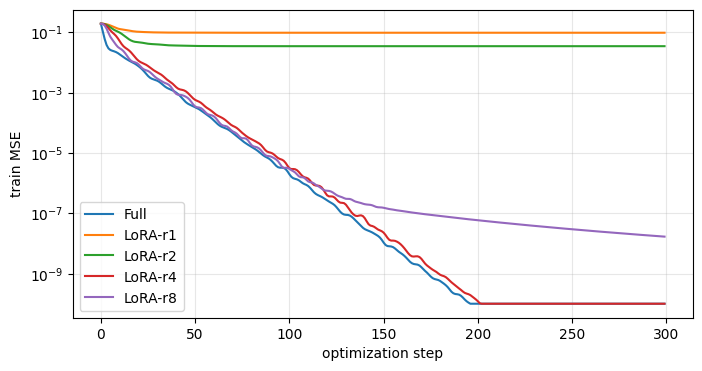

In [8]:
def fit(model, steps=300, lr=0.03):
    params = [p for p in model.parameters() if p.requires_grad]  # TODO ⑨
    optimizer = torch.optim.Adam(params, lr=lr)
    history = []
    model.train()
    for step in range(steps):
        optimizer.zero_grad(set_to_none=True)
        loss = F.mse_loss(model(X_train), Y_train)
        loss.backward()  # TODO ⑩
        optimizer.step()  # TODO ⑪
        history.append(loss.item())
    model.eval()
    with torch.no_grad():
        test_mse = F.mse_loss(model(X_test), Y_test).item()
    return history, test_mse

def trainable_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

with torch.no_grad():
    baseline_mse = F.mse_loss(base_task(X_test), Y_test).item()
results, histories, trained = [], {}, {}
for name, rank in [('Full', None), ('LoRA-r1', 1), ('LoRA-r2', 2), ('LoRA-r4', 4), ('LoRA-r8', 8)]:
    seed_everything(42)
    model = copy.deepcopy(base_task) if rank is None else LoRALinear(base_task, rank, alpha=rank)
    # Full도 bias는 고정: 같은 가중치 적응 문제를 비교합니다.
    if rank is None:
        model.bias.requires_grad_(False)
    hist, mse = fit(model)
    results.append((name, trainable_count(model), mse))
    histories[name], trained[name] = hist, model

print(f'학습 전 평가 MSE: {baseline_mse:.6f}')
for name, count, mse in results:
    print(f'{name:10s} trainable={count:4d}, test MSE={mse:.6f}')
plt.figure(figsize=(8, 4))
for name, history in histories.items():
    plt.semilogy(np.maximum(history, 1e-10), label=name)
plt.xlabel('optimization step'); plt.ylabel('train MSE'); plt.legend(); plt.grid(alpha=.3); plt.show()


In [9]:
# ✅ 성능 순위를 정답으로 강제하지 않고 구현의 성질을 확인합니다.
assert all(math.isfinite(mse) for _, _, mse in results)
for name, model in trained.items():
    if isinstance(model, LoRALinear):
        torch.testing.assert_close(model.base.weight, base_task.weight, rtol=0, atol=0)
        assert trainable_count(model) == model.r * (K + D)
        rank_now = torch.linalg.matrix_rank((model.B @ model.A).detach()).item()
        assert rank_now <= model.r
print('✅ 기본 가중치 고정 및 rank·파라미터 수 확인')


✅ 기본 가중치 고정 및 rank·파라미터 수 확인


### [보조] 3-2 표 채우기
안내대로 `TRUE_RANK=16`으로 바꿔 다시 실행하는 것과 같은 절차를 함수로 묶어, 두 설정을 한 번에 실행합니다. 데이터 생성 코드·시드·순서가 위 셀과 같으므로 TRUE_RANK=4 결과는 위 실행과 같습니다. 실행 후에는 Part 4에서 쓰는 rank-4 데이터로 되돌립니다.

함께 출력하는 **이론 하한**은, 입력이 $x\sim\mathcal N(0,I)$일 때 test MSE의 기댓값이 $\|BA-\Delta W_{\mathrm{true}}\|_F^2/D$이고 rank-$r$ 근사의 최소 오차가 $\sum_{i>r}\sigma_i^2$ (Eckart–Young 정리)라는 데서 나온 값입니다.


In [10]:
def run_rank_experiment(true_rank):
    global X_train, X_test, Y_train, Y_test
    seed_everything(42)
    bt = nn.Linear(K, D).to(device)
    with torch.no_grad():
        u, _ = torch.linalg.qr(torch.randn(D, true_rank, device=device))
        v, _ = torch.linalg.qr(torch.randn(K, true_rank, device=device))
        sv = torch.linspace(1.5, 0.5, true_rank, device=device)
        dt = (u * sv) @ v.T
        tw = bt.weight.detach() + dt
        X_train = torch.randn(512, K, device=device)
        X_test = torch.randn(256, K, device=device)
        Y_train = F.linear(X_train, tw, bt.bias)
        Y_test = F.linear(X_test, tw, bt.bias)
        base_mse = F.mse_loss(bt(X_test), Y_test).item()
    row = {}
    for name, rank in [('Full', None), ('LoRA-r1', 1), ('LoRA-r2', 2), ('LoRA-r4', 4), ('LoRA-r8', 8)]:
        seed_everything(42)
        model = copy.deepcopy(bt) if rank is None else LoRALinear(bt, rank, alpha=rank)
        if rank is None:
            model.bias.requires_grad_(False)
        _, mse = fit(model)
        row[name] = mse
    floor = {'Full': 0.0}
    for rr in (1, 2, 4, 8):
        floor[f'LoRA-r{rr}'] = (sv[rr:] ** 2).sum().item() / D
    return base_mse, row, floor

_saved = (X_train, X_test, Y_train, Y_test)
rank_table = {tr: run_rank_experiment(tr) for tr in (4, 16)}
X_train, X_test, Y_train, Y_test = _saved  # Part 4용 데이터 복원

cols = ['Full', 'LoRA-r1', 'LoRA-r2', 'LoRA-r4', 'LoRA-r8']
lines = ['| TRUE_RANK | 학습 전 MSE | Full MSE | r1 MSE | r2 MSE | r4 MSE | r8 MSE |',
         '|---|---|---|---|---|---|---|']
for tr, (bm, row, floor) in rank_table.items():
    lines.append(f'| {tr} (실험) | {bm:.4f} | ' + ' | '.join(f'{row[c]:.2e}' for c in cols) + ' |')
    lines.append(f'| {tr} (이론 하한) | - | ' + ' | '.join(f'{floor[c]:.4f}' for c in cols) + ' |')
table_md = '\n'.join(lines)
print(table_md)
try:
    from IPython.display import Markdown, display
    display(Markdown(table_md))
except ImportError:
    pass


| TRUE_RANK | 학습 전 MSE | Full MSE | r1 MSE | r2 MSE | r4 MSE | r8 MSE |
|---|---|---|---|---|---|---|
| 4 (실험) | 0.1797 | 8.20e-15 | 9.74e-02 | 4.06e-02 | 1.07e-14 | 2.09e-08 |
| 4 (이론 하한) | - | 0.0000 | 0.0961 | 0.0394 | 0.0000 | 0.0000 |
| 16 (실험) | 0.7690 | 2.01e-14 | 6.74e-01 | 5.81e-01 | 4.26e-01 | 1.99e-01 |
| 16 (이론 하한) | - | 0.0000 | 0.6359 | 0.5503 | 0.4020 | 0.1870 |


| TRUE_RANK | 학습 전 MSE | Full MSE | r1 MSE | r2 MSE | r4 MSE | r8 MSE |
|---|---|---|---|---|---|---|
| 4 (실험) | 0.1797 | 8.20e-15 | 9.74e-02 | 4.06e-02 | 1.07e-14 | 2.09e-08 |
| 4 (이론 하한) | - | 0.0000 | 0.0961 | 0.0394 | 0.0000 | 0.0000 |
| 16 (실험) | 0.7690 | 2.01e-14 | 6.74e-01 | 5.81e-01 | 4.26e-01 | 1.99e-01 |
| 16 (이론 하한) | - | 0.0000 | 0.6359 | 0.5503 | 0.4020 | 0.1870 |

**3-2.** 두 TRUE_RANK 설정에서 결과를 기록하세요. rank와 오차의 관계, 그리고 이것으로 실제 언어모델에서도 r=1이면 충분하다고 결론 내릴 수 있는지 설명하세요.

| TRUE_RANK | Full MSE | r1 MSE | r2 MSE | r4 MSE | r8 MSE |
|---|---|---|---|---|---|
| 4 | | | | | |
| 16 | | | | | |


**답변:**

| TRUE_RANK | Full MSE | r1 MSE | r2 MSE | r4 MSE | r8 MSE |
|---|---|---|---|---|---|
| 4 | 8.20e-15 | 9.74e-02 | 4.06e-02 | 1.07e-14 | 2.09e-08 |
| 16 | 2.01e-14 | 6.74e-01 | 5.81e-01 | 4.26e-01 | 1.99e-01 |
| 이론값 (4) | 0 | 0.0961 | 0.0394 | 0 | 0 |
| 이론값 (16) | 0 | 0.6359 | 0.5503 | 0.4020 | 0.1870 |

※ 실험값은 위 보조 셀 출력(test MSE)이다. 학습 전 test MSE는 TRUE_RANK=4에서 0.1797, 16에서 0.7690이다.

**rank와 오차의 관계**
- 입력이 표준정규분포이므로 test MSE의 기댓값은 $\|BA - \Delta W_{\mathrm{true}}\|_F^2 / D$이고, rank-$r$ 행렬이 낼 수 있는 최소 오차는 정답 변화량의 $r$번째 이후 특이값 제곱합 $\sum_{i>r}\sigma_i^2$이다(Eckart–Young). 표의 이론값이 이 값이다.
- 실험값은 이론값과 몇 % 이내로 일치한다(예: TRUE_RANK=16에서 실험/이론 비율이 r1~r8 모두 약 1.06). 차이는 최적화가 덜 된 탓이 아니다. 학습 곡선에서 r1·r2는 50 step 이전에 이미 평탄해졌다. 차이는 학습 512개·평가 256개라는 유한 표본에서 표본 공분산이 $I$와 정확히 같지 않기 때문이다. 같은 이유로 학습 전 MSE도 이론값(4: 0.1898, 16: 0.7296)과 조금 다르다. 따라서 이론값은 모집단 기준 값이고, 유한 표본의 MSE가 반드시 그 위에 오는 엄밀한 하한은 아니다.
- **TRUE_RANK=4:** $r < 4$인 r1(0.097), r2(0.041)는 표현할 수 없는 방향이 남아 오차가 이론값 근처에서 멈춘다. $r \ge 4$인 r4(1.07e-14), r8(2.09e-08)은 정답을 표현할 수 있어 Full(8.20e-15)처럼 오차가 사실상 0이다. 다만 r을 4→8로 늘려도 더 좋아지지 않았고, 오히려 r8은 300 step 시점에도 학습 곡선이 천천히 내려가는 중이라 r4보다 오차가 컸다. 필요 이상으로 큰 r은 이 실험에서 수렴만 느리게 했다.
- **TRUE_RANK=16:** 모든 LoRA 설정이 $r < 16$이라 rank를 늘릴수록 오차가 단조 감소(0.674 → 0.581 → 0.426 → 0.199)하지만, r8도 0이 되지 않는다. 반면 Full은 이 문제가 볼록 최소제곱이라 0에 수렴한다.
- 정리하면 오차는 **"필요한 변화량의 rank에 비해 r이 충분한가"**로 정해지며, r 자체의 크기로 정해지지 않는다.

**실제 언어모델에서도 r=1이면 충분하다고 결론 낼 수 있나?** → 없다.
- 이 실험에서는 r=1이 TRUE_RANK=4인 경우에도 충분하지 않았다(0.097, 학습 전 0.180의 절반 정도). 결과는 **직접 설계한** 정답 변화량의 rank에 따라 정해진 것이다.
- 실제 사전학습 모델에서 필요한 $\Delta W$의 rank는 알려져 있지 않고, 모델·작업·적용 위치에 따라 다르다. 논문 Table 6에서 GPT-3의 $W_q, W_v$에 r=1만 써도 큰 r과 비슷한 성능을 보인 것은 해당 작업(WikiSQL, MNLI)에서의 **경험적 관찰**이다. 논문도 §7.2에서 작은 r이 모든 작업에 통하리라 기대하지 않는다고 하며, 사전학습과 다른 언어의 작업처럼 차이가 큰 경우를 예로 든다.
- 또 이 실험은 선형 회귀 하나에 합성 데이터라, 비선형·다층 구조에서 여러 층의 변화량이 상호작용하는 상황은 반영하지 못한다.


## Part 4. 병합과 Transformer 적용
### 문제 4-1. 병합 전후 출력 비교
병합은 기존 가중치에 스케일된 BA를 더하는 것입니다. 병합한 Linear에는 LoRA 경로를 다시 추가하지 않습니다.


In [11]:
trained_layer = trained['LoRA-r4']
merged = trained_layer.to_merged_linear()  # TODO ⑫
with torch.no_grad():
    y_before = trained_layer(X_test)
    y_after = merged(X_test)
torch.testing.assert_close(y_before, y_after, rtol=1e-4, atol=1e-5)
assert isinstance(merged, nn.Linear)
assert not any(p.requires_grad for p in merged.parameters())
print('최대 출력 차이:', (y_before - y_after).abs().max().item())
print('✅ 병합된 층은 원래 크기의 Linear 하나입니다.')

# 모듈만 저장한 체크포인트: 기본 가중치는 여전히 필요합니다.
torch.save({'A': trained_layer.A.detach().cpu(), 'B': trained_layer.B.detach().cpu(),
            'r': trained_layer.r, 'scale': trained_layer.scale}, 'lora_adapter.pt')
print('lora_adapter.pt 저장 완료')


최대 출력 차이: 4.76837158203125e-07
✅ 병합된 층은 원래 크기의 Linear 하나입니다.
lora_adapter.pt 저장 완료


### 문제 4-2. Query와 Value에 각각 LoRA를 적용하세요
아래는 한 head의 self-attention입니다. embedding, MLP, LayerNorm 등을 갖춘 전체 언어모델은 아닙니다. 원 논문 대부분 실험의 적용 위치를 확인하기 위한 작은 예시입니다.
$$Q=xW_q^\top,\ K=xW_k^\top,\ V=xW_v^\top,\quad H=\mathrm{softmax}(QK^\top/\sqrt d)V$$
Wq용 A,B와 Wv용 A,B는 별도로 학습합니다.


In [12]:
class TinyAttention(nn.Module):
    def __init__(self, d=32):
        super().__init__()
        self.q_proj = nn.Linear(d, d, bias=False)
        self.k_proj = nn.Linear(d, d, bias=False)
        self.v_proj = nn.Linear(d, d, bias=False)
        self.o_proj = nn.Linear(d, d, bias=False)
        self.d = d
    def forward(self, x):
        q, k, v = self.q_proj(x), self.k_proj(x), self.v_proj(x)
        weights = (q @ k.transpose(-2, -1) / math.sqrt(self.d)).softmax(dim=-1)
        return self.o_proj(weights @ v)

seed_everything(17)
attention = TinyAttention()
adapted_attention = copy.deepcopy(attention)
adapted_attention.requires_grad_(False)
adapted_attention.q_proj = LoRALinear(adapted_attention.q_proj, r=4, alpha=4)  # TODO ⑬
adapted_attention.v_proj = LoRALinear(adapted_attention.v_proj, r=4, alpha=4)  # TODO ⑭

tokens = torch.randn(2, 6, 32)  # batch, sequence length, hidden dimension
torch.testing.assert_close(attention(tokens), adapted_attention(tokens))
names = [n for n,p in adapted_attention.named_parameters() if p.requires_grad]
print('학습하는 파라미터:', names)
assert set(names) == {'q_proj.A', 'q_proj.B', 'v_proj.A', 'v_proj.B'}
assert trainable_count(adapted_attention) == 2 * 4 * (32 + 32)
assert adapted_attention(tokens).shape == (2, 6, 32)
assert adapted_attention.q_proj.A is not adapted_attention.v_proj.A
print('✅ Q·V에 각각 추가한 LoRA 행렬만 학습 대상입니다.')


학습하는 파라미터: ['q_proj.A', 'q_proj.B', 'v_proj.A', 'v_proj.B']
✅ Q·V에 각각 추가한 LoRA 행렬만 학습 대상입니다.


**4-3.** 병합 후 추가 추론 연산이 없는 이유와, 서로 다른 작업의 LoRA를 한 배치에서 쓰기 어려운 이유를 쓰세요.


**답변:**

**병합 후 추가 추론 연산이 없는 이유**
학습이 끝나면 $W = W_0 + \frac{\alpha}{r}BA$를 한 번만 계산해 저장한다. $BA$는 $d\times k$로 $W_0$와 같은 크기이므로 병합된 층은 원래와 같은 크기의 `nn.Linear` 하나이고, 추론 때도 원래 모델처럼 행렬곱 1번만 한다. 4-1에서 병합 전후 최대 출력 차이가 약 4.8e-07로 float32 수치 오차 수준임을 확인했다. 층이 늘지 않으므로, 층을 순차적으로 추가하는 Adapter 방식과 달리 지연 시간이 늘지 않는다(논문 §4.1, Table 1 비교).

**서로 다른 작업의 LoRA를 한 배치에서 쓰기 어려운 이유**
병합하면 작업별 변화량이 가중치 안에 들어가, 그 가중치는 **한 작업 전용**이 된다. 배치 안의 샘플마다 작업이 다르면 샘플마다 다른 $W$가 필요하므로 하나의 행렬곱으로 처리할 수 없다. 방법은 두 가지다.
1. 작업별로 배치를 나눈다.
2. 병합하지 않고 $W_0x + s\,B_i A_i x$를 샘플마다 다른 $(A_i, B_i)$로 동적으로 계산한다. 이 경우 추가 연산이 생겨 "추론 지연 없음"이라는 장점을 일부 포기하게 된다.

논문 §4.2도 A, B를 W에 흡수하는 경우 이 점을 한계로 언급한다. 대신 작업 전환 자체는 $BA$를 빼고 $B'A'$를 더하면 되므로 메모리 부담이 적고 빠르다.


## Part 5. 서술형 복습
**5-1.** Full fine-tuning의 학습 비용과 작업별 저장·배포 비용을 구분해서 설명하세요. 작은 어댑터만 저장하면 기본 모델이 없어도 추론할 수 있나요?

**5-2.** 낮은 내재적 차원과 낮은 내재적 랭크의 차이를 설명하세요. 선행연구가 LoRA의 가설을 증명한 것인가요?

**5-3.** 논문 Table 4에서 4.7M LoRA의 WikiSQL은 73.4, Full은 73.8입니다. “LoRA가 모든 지표에서 Full보다 높다”라고 써도 될까요?

**5-4.** r을 늘리면 성능이 반드시 좋아질까요? 적용 위치와 작업의 특성을 함께 고려하세요.

**5-5.** 이 과제에서 확인한 사실과, 이 과제만으로 확인할 수 없는 논문의 주장을 각각 두 가지씩 쓰세요.


**답변:**

**5-1. 학습 비용 vs 저장·배포 비용**
- **학습 비용:** Full fine-tuning은 모든 파라미터의 기울기와 옵티마이저 상태(Adam은 파라미터당 2개)를 메모리에 둔다. LoRA는 기본 가중치가 고정이므로 A, B에 대해서만 기울기·옵티마이저 상태가 필요하고, 이 부분의 메모리가 크게 준다. 논문은 GPT-3 175B에서 학습 VRAM이 1.2TB → 350GB로 줄고 학습 속도가 약 25% 빨라졌다고 보고한다(§4.2). 다만 고정된 층을 통과하는 순전파·역전파와 활성값 저장은 여전히 필요하므로 연산량이 파라미터 수 비율만큼 줄지는 않는다.
- **저장·배포 비용:** Full은 작업마다 모델 전체(GPT-3 기준 약 350GB)를 따로 저장해야 한다. LoRA는 기본 모델 하나를 공유하고 작업별로 A, B만 저장하면 된다(논문: r=4, $W_q, W_v$에 적용 시 약 35MB, §4.2).
- **어댑터만으로 추론 가능한가?** 불가능하다. 어댑터에는 변화량 $\Delta W = BA$만 들어 있고, 출력은 $h = W_0x + sBAx$이므로 $W_0$가 반드시 필요하다. 4-1에서 저장한 `lora_adapter.pt`에도 A, B, r, scale만 있다. 또 학습 때 쓴 것과 **같은 버전의** 기본 가중치여야 의미가 있다.

**5-2. 낮은 내재적 차원 vs 낮은 내재적 랭크**
- **내재적 차원(intrinsic dimension):** Li et al.(2018), Aghajanyan et al.(2020)의 개념이다. 전체 파라미터 벡터를 $\theta = \theta_0 + Pz$처럼 **무작위로 고정된** 저차원 부분공간에서만 최적화했을 때 Full 성능의 일정 비율(예: 90%)에 도달하는 최소 차원 $\dim z$를 말한다. 모델 전체 파라미터 공간에 대한 성질이다.
- **내재적 랭크(intrinsic rank, LoRA의 가설):** 각 가중치 **행렬**의 변화량 $\Delta W$가 낮은 rank를 갖는다는 가설이다. 행렬 단위의 구조에 대한 주장이며, 부분공간(A, B)도 고정이 아니라 학습된다.
- 두 개념은 다르다. 전체 파라미터 공간에서 소수의 방향으로 충분하다고 해서 각 층의 $\Delta W$가 저랭크라는 것이 수학적으로 따라 나오지는 않는다.
- **선행연구가 가설을 증명했는가?** 아니다. 선행연구는 사전학습 모델의 미세조정이 낮은 내재적 차원을 가진다는 **실험적 관찰**을 제공했고, LoRA는 이를 근거로 "변화량도 낮은 내재적 랭크를 가질 것"이라는 **가설을 세웠다**(§1, §4.1). 이 가설은 LoRA 논문 §7의 실험(작은 r로도 성능 유지, r=8과 r=64가 학습한 상위 방향의 부분공간 유사도 분석 등)으로 **경험적으로 뒷받침**될 뿐, 일반적으로 증명된 것은 아니다.

**5-3. "LoRA가 모든 지표에서 Full보다 높다"라고 써도 되는가?**
안 된다. 문제에 주어진 WikiSQL에서 4.7M LoRA(73.4)는 Full(73.8)보다 **낮다.** 반례가 하나라도 있으면 "모든 지표"라는 주장은 틀린다. Table 4에서 LoRA는 MNLI-m, SAMSum에서는 Full보다 높지만 차이가 작고, 논문 캡션에도 작업별 변동폭(WikiSQL은 약 ±0.5%)이 제시되어 있어 작은 차이를 우열로 단정하기도 어렵다. 적절한 표현은 "훨씬 적은 학습 파라미터로 Full과 **비슷하거나 일부 작업에서 더 나은** 성능" 정도이다.

**5-4. r을 늘리면 성능이 반드시 좋아지는가?**
아니다.
- **이 과제:** TRUE_RANK=4에서 r4(1.07e-14)와 r8(2.09e-08)은 모두 오차가 사실상 0이라 r을 늘린 이득이 없었고, r8은 300 step 안에 r4만큼 수렴하지도 못했다. 필요한 변화량의 rank를 넘어서면 r을 키워도 표현력이 더 늘지 않는다. 반대로 TRUE_RANK=16처럼 필요한 rank가 크면 r을 늘릴수록 좋아졌다(0.674 → 0.199). 결국 작업에 필요한 rank에 따라 달라진다.
- **적용 위치:** 논문 Table 6에서 $W_q, W_v$에 적용하면 r=1~64가 비슷한 성능이었지만, $W_q$에만 적용하면 작은 r에서 성능이 떨어졌다. Table 5에서는 같은 파라미터 예산에서 한 종류 행렬에 큰 r을 쓰는 것보다 여러 행렬($W_q, W_v$ 등)에 작은 r을 나눠 쓰는 편이 더 좋았다. 즉 r보다 "어디에 적용하는가"가 더 중요할 수 있다.
- **작업 특성:** 사전학습 분포와 거리가 먼 작업(예: 다른 언어)은 큰 변화가 필요할 수 있어 작은 r이 부족할 수 있다(§7.2). 반대로 데이터가 적은 작업에서는 r을 키우면 학습 파라미터가 늘어 과적합 위험이 생기고, 메모리·저장 비용도 는다.
- 실제 결과는 학습률·$\alpha$ 같은 하이퍼파라미터와도 얽혀 있어, r만 바꿔서 성능이 단조 증가하리라 기대하기 어렵다.

**5-5. 확인한 사실 / 확인할 수 없는 주장**
- 이 과제에서 **확인한 사실**
  1. B=0 초기화에서는 학습 시작 시 출력이 기본 모델과 같고, 첫 역전파에서는 B만 기울기를 받으며(A 0.0, B ≈ 0.104) 한 번 갱신된 뒤 A도 기울기를 받는다. A, B를 모두 0으로 두면 두 기울기가 0이라 학습되지 않는다(Part 2).
  2. 학습한 LoRA를 기본 가중치에 병합하면 원래 크기의 Linear 하나가 되고 출력 차이는 약 4.8e-07로 수치 오차 수준이다. 즉 병합 후 추가 추론 연산이 없다(Part 4-1). 이와 함께 학습 파라미터 수가 $r(d+k)$이고 기본 가중치가 바뀌지 않으며, $\mathrm{rank}(BA)\le r$임도 확인했다.
  3. (추가) 정답 변화량의 rank보다 r이 작으면 오차가 Eckart–Young 이론값 근처에서 멈추고 0으로 가지 않는다(Part 3).
- 이 과제만으로 **확인할 수 없는 주장**
  1. 실제 사전학습 언어모델(GPT-3, RoBERTa 등)에서 LoRA가 Full fine-tuning과 비슷하거나 더 나은 성능을 낸다는 주장과, 실제 $\Delta W$가 낮은 내재적 랭크를 갖는다는 가설 자체. 이 과제의 정답 변화량은 저랭크로 **설계**한 것이기 때문이다.
  2. GPU 메모리 감소(1.2TB → 350GB), 학습 속도 약 25% 향상, 체크포인트 크기 약 10,000배 감소 같은 대규모 시스템 수준의 효율 주장. 이 과제는 작은 층을 CPU에서 다룬 축소 실습이다.


## 참고 자료
- [LoRA 논문](https://arxiv.org/abs/2106.09685): §2, §4.1–4.2, Table 4, §7.1–7.2
- [Microsoft 공식 LoRA 구현](https://github.com/microsoft/LoRA): 공식 라이브러리와 이 과제의 설명용 구현은 초기화 등의 세부가 다릅니다.
- [PyTorch F.linear](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.linear.html)

원 논문의 실험 성능을 재현하려면 공식 구현의 데이터·모델·학습 설정이 필요합니다. 이 과제는 메커니즘을 확인하는 축소 실습입니다.
